# EDA: Betis Predictor

**Objetivo del proyecto:** predecir la probabilidad de victoria, empate o derrota
del Real Betis en LaLiga y comparar el modelo con las cuotas del mercado.

**Datos:** 3.909 partidos de LaLiga (2016/17 a 2026/27, esta última en curso),
obtenidos de [football-data.co.uk](https://www.football-data.co.uk/).

**Objetivo de este notebook:** entender los datos antes de modelar.

## 0. Carga y revisión de los datos

Cargamos el CSV limpio (`data/processed/laliga_matches.csv`) y revisamos tipos
y valores perdidos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/processed/laliga_matches.csv", parse_dates=["Date"])
print(df.shape)
df.head()

(3909, 34)


,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HS,AS,HST,AST,...,AvgH,AvgD,AvgA,AvgCH,AvgCD,AvgCA,B365CH,B365CD,B365CA,Season
0,2016-08-19,La Coruna,Eibar,2,1,H,11,12,6,6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1617
1,2016-08-19,Malaga,Osasuna,1,1,D,14,8,4,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1617
2,2016-08-20,Barcelona,Betis,6,2,H,30,6,12,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1617
3,2016-08-20,Granada,Villarreal,1,1,D,7,12,1,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1617
4,2016-08-20,Sevilla,Espanol,6,4,H,16,10,11,7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1617


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3909 entries, 0 to 3908
Data columns (total 34 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      3909 non-null   datetime64[us]
 1   HomeTeam  3909 non-null   str           
 2   AwayTeam  3909 non-null   str           
 3   FTHG      3909 non-null   int64         
 4   FTAG      3909 non-null   int64         
 5   FTR       3909 non-null   str           
 6   HS        3909 non-null   int64         
 7   AS        3909 non-null   int64         
 8   HST       3909 non-null   int64         
 9   AST       3909 non-null   int64         
 10  HF        3909 non-null   int64         
 11  AF        3909 non-null   int64         
 12  HC        3909 non-null   int64         
 13  AC        3909 non-null   int64         
 14  HY        3909 non-null   int64         
 15  AY        3909 non-null   int64         
 16  HR        3909 non-null   int64         
 17  AR        3909 non-null  

**Observaciones:**
- El dataset tiene 3.909 filas y 34 columnas.
- `Date` es una fecha real (`datetime64`).
- Resultados y estadísticas del partido están completos (sin valores perdidos).
- Las cuotas de cierre de la media del mercado (`AvgC*`) solo existen desde
  2019/20; las de Pinnacle (`PSC*`) fallan en 2025/26 y 2026/27.
- Por tanto, el benchmark principal será `AvgC*` y el secundario `PSC*`.

## 1. Ventaja de jugar en casa
¿Con qué frecuencia gana el local, empata o gana el visitante?

FTR
H    45.5
D    26.2
A    28.3
Name: proportion, dtype: float64


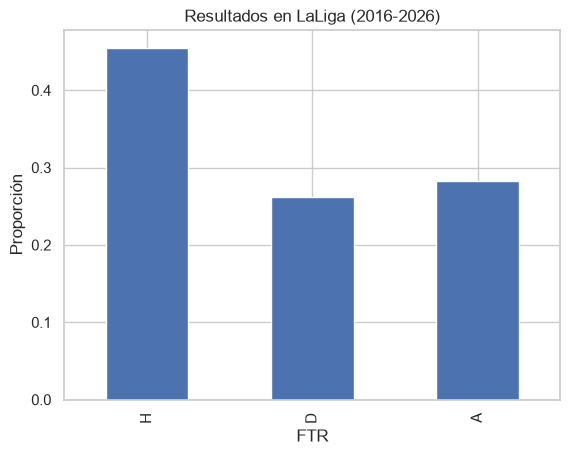

In [3]:
resultados = df["FTR"].value_counts(normalize=True).reindex(["H", "D", "A"])
print((resultados * 100).round(1))

resultados.plot(kind="bar")
plt.title("Resultados en LaLiga (2016-2026)")
plt.ylabel("Proporción")
plt.show()

**Conclusión:**

| Resultado | % |
|---|---|
| Gana el local | 45,5 |
| Empate | 26,2 |
| Gana el visitante | 28,3 |

- Hay ventaja de jugar en casa: el local gana 17 puntos porcentuales más que
  el visitante. `local/visitante` debe ser una variable del modelo.
- Los empates son más de una cuarta parte de los partidos y son la clase más
  difícil de predecir. Por eso evaluaremos con métricas probabilísticas
  (log-loss, Brier, RPS) y no solo con la *accuracy*.
- Predecir siempre estas tres proporciones es la **línea base** más simple;
  su log-loss (≈ 1,07) es el suelo que el modelo debe superar.

## 2. Distribución de goles

Los goles por equipo y partido suelen modelarse con una distribución de Poisson,
que es la base de modelos clásicos como Dixon-Coles. Comprobamos si el supuesto
es razonable con datos reales.

Media de goles por equipo y partido: 1.31
Varianza: 1.44


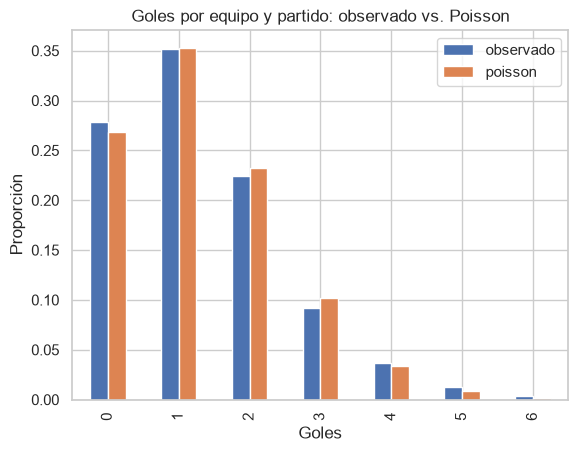

In [4]:
goles = pd.concat([df["FTHG"], df["FTAG"]])
print("Media de goles por equipo y partido:", goles.mean().round(2))
print("Varianza:", goles.var().round(2))

obs = goles.value_counts(normalize=True).sort_index().loc[:6]

from scipy.stats import poisson
esp = pd.Series(poisson.pmf(obs.index, goles.mean()), index=obs.index)

pd.DataFrame({"observado": obs, "poisson": esp}).plot(kind="bar")
plt.title("Goles por equipo y partido: observado vs. Poisson")
plt.xlabel("Goles")
plt.ylabel("Proporción")
plt.show()

**Observaciones:**
- Media de goles por equipo y partido: 1,31. Varianza: 1,44.
- El cociente varianza/media es ≈ 1,10: ligera sobredispersión.
- El ajuste a la Poisson es muy bueno. Las mayores diferencias están en
  0 goles (algo más frecuente de lo esperado) y en 3 goles (algo menos),
  con colas (4+) ligeramente más pesadas.
- Esto es coherente con la mezcla de equipos de distinto nivel y con una
  posible dependencia entre los goles de local y visitante (corrección
  de Dixon-Coles para marcadores bajos).

### Contrastes de bondad de ajuste

Aplicamos dos contrastes, separando goles del local y del visitante para no
mezclar sus distintos promedios:

1. **Índice de dispersión.** Bajo una Poisson, `(n-1)·s²/x̄ ~ χ²(n-1)`.
2. **χ² de Pearson de bondad de ajuste**, agrupando "4 o más goles" en una sola
   categoría para que los esperados sean suficientes. Grados de libertad:
   `k - 1 - 1`, porque se estima λ con los datos.

**Matiz importante:** aunque cada equipo marque goles según una Poisson, mezclar
equipos con distinto λ produce sobredispersión en el conjunto. Rechazar la
Poisson en el total no implica que el modelo Poisson sea inadecuado por equipo.

In [5]:
from scipy import stats

# --- 1. Índice de dispersión, por separado local y visitante ---
for nombre, serie in [("Local", df["FTHG"]), ("Visitante", df["FTAG"])]:
    media, var = serie.mean(), serie.var(ddof=1)
    n = len(serie)
    # Estadístico de dispersión: (n-1)*var/media ~ chi2(n-1) bajo Poisson
    stat = (n - 1) * var / media
    p_val = 2 * min(stats.chi2.cdf(stat, n - 1), stats.chi2.sf(stat, n - 1))
    print(f"{nombre}: media={media:.3f}  var={var:.3f}  "
          f"índice={var/media:.3f}  p-valor={p_val:.3f}")

# --- 2. Chi-cuadrado de bondad de ajuste (goles del local) ---
x = df["FTHG"]
lam = x.mean()
obs = x.value_counts().sort_index()
obs = pd.concat([obs.loc[:3], pd.Series({"4+": obs.loc[4:].sum()})])  # agrupar 4 o más
p = [stats.poisson.pmf(k, lam) for k in range(4)]
p.append(1 - sum(p))                                                  # P(X >= 4)
esp = np.array(p) * len(x)

chi2_stat = ((obs.values - esp) ** 2 / esp).sum()
gl = len(obs) - 1 - 1                       # k - 1 - (parámetros estimados)
p_chi2 = stats.chi2.sf(chi2_stat, gl)

print(pd.DataFrame({"observado": obs.values, "esperado": esp.round(1)}, index=obs.index))
print(f"\nChi2={chi2_stat:.2f}, gl={gl}, p-valor={p_chi2:.3f}")

Local: media=1.492  var=1.602  índice=1.074  p-valor=0.001
Visitante: media=1.138  var=1.209  índice=1.063  p-valor=0.006
    observado  esperado
0         901     879.5
1        1327    1311.9
2         954     978.5
3         447     486.5
4+        280     252.5

Chi2=7.51, gl=3, p-valor=0.057


**Resultados:**

| | Media | Varianza | Índice | p-valor |
|---|---|---|---|---|
| Local | 1,492 | 1,602 | 1,074 | 0,001 |
| Visitante | 1,138 | 1,209 | 1,063 | 0,006 |

- χ² de bondad de ajuste (goles del local): χ² = 7,51, gl = 3, p = 0,057.

**Interpretación:** el contraste de dispersión rechaza la igualdad de media
y varianza, pero el índice es solo ≈ 1,07: la desviación es pequeña en la
práctica. El χ² no rechaza la Poisson al 5 % (p marginal). Las diferencias
se concentran en un exceso de 0 y de 4+ goles y un déficit de 2 y 3.

**Decisión para el modelado:** usar una Poisson con λ distinto por equipo
(ataque/defensa) y por condición de local/visitante, y valorar la corrección
de Dixon-Coles para marcadores bajos.